# 01 · Exploratory data analysis (HAM10000)
Class balance, age and body-site distributions, missing values, and a visual pass over
the images to note acquisition artifacts (rulers, ink, hair, dark corners) that we will
look for again in the SHAP maps.

In [1]:
import sys; sys.path.insert(0, "..")
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from src.data import CLASSES, URGENT, load_image, load_metadata
from src.artifacts import artifact_flags

plt.rcParams.update({"figure.dpi": 110, "savefig.bbox": "tight"})
df = load_metadata("../data/ham")
split = pd.read_csv("../splits/split.csv").set_index("image_id")["split"]
df["split"] = df["image_id"].map(split)
print(len(df), "images,", df.lesion_id.nunique(), "lesions")

10015 images, 7470 lesions


## Class balance: 67% of images are nevi

{'akiec': 0.033, 'bcc': 0.051, 'bkl': 0.11, 'df': 0.011, 'mel': 0.111, 'nv': 0.669, 'vasc': 0.014}


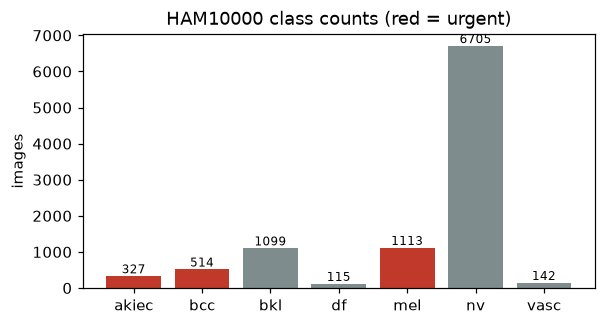

In [2]:
counts = df.dx.value_counts().reindex(CLASSES)
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(counts.index, counts.values, color=["#c0392b" if c in URGENT else "#7f8c8d" for c in counts.index])
for i, v in enumerate(counts.values):
    ax.text(i, v + 80, f"{v}", ha="center", fontsize=8)
ax.set_title("HAM10000 class counts (red = urgent)")
ax.set_ylabel("images")
fig.savefig("../figures/eda_class_counts.png")
print((counts / counts.sum()).round(3).to_dict())

## Age and body location per class

dx,akiec,bcc,bkl,df,mel,nv,vasc
localization,,,,,,,
abdomen,0.02,0.04,0.04,0.03,0.06,0.13,0.19
acral,0.00,0.00,0.00,0.00,0.00,0.00,0.00
back,0.09,0.36,0.18,0.02,0.29,0.21,0.15
chest,0.04,0.09,0.07,0.00,0.06,0.03,0.04
ear,0.01,0.00,0.01,0.00,0.02,0.00,0.00
face,0.35,0.20,0.29,0.00,0.09,0.01,0.06
foot,0.00,0.01,0.00,0.02,0.03,0.04,0.00
genital,0.00,0.00,0.00,0.01,0.00,0.01,0.00
hand,0.04,0.00,0.01,0.00,0.00,0.01,0.04


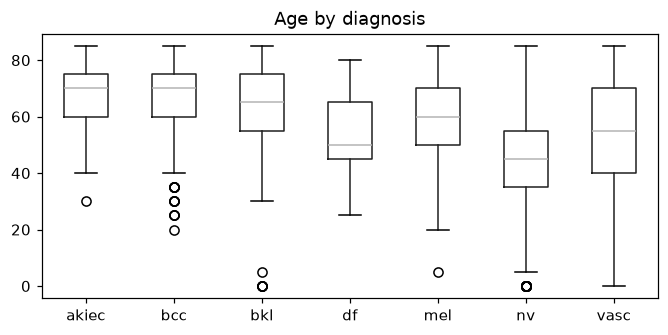

In [3]:
fig, ax = plt.subplots(figsize=(7, 3.2))
df.boxplot(column="age", by="dx", ax=ax, grid=False)
ax.set_title("Age by diagnosis"); fig.suptitle(""); ax.set_xlabel("")
fig.savefig("../figures/eda_age_by_class.png")

loc = pd.crosstab(df.localization, df.dx, normalize="columns").round(2)
loc

## Missing values and "unknown" categories

In [4]:
print("missing age:", df.age.isna().sum())
print("sex values:", df.sex.value_counts().to_dict())
print("localization == unknown:", (df.localization == "unknown").sum())
print("images per lesion:", df.groupby("lesion_id").size().value_counts().sort_index().to_dict())
print("diagnosis type:", df.dx_type.value_counts().to_dict())

missing age: 57
sex values: {'male': 5406, 'female': 4552, 'unknown': 57}
localization == unknown: 234
images per lesion: {1: 5514, 2: 1423, 3: 490, 4: 34, 5: 5, 6: 4}
diagnosis type: {'histo': 5340, 'follow_up': 3704, 'consensus': 902, 'confocal': 69}


## Visual pass: a sample per class
A contact sheet of random images per class, used to note artifacts by eye.

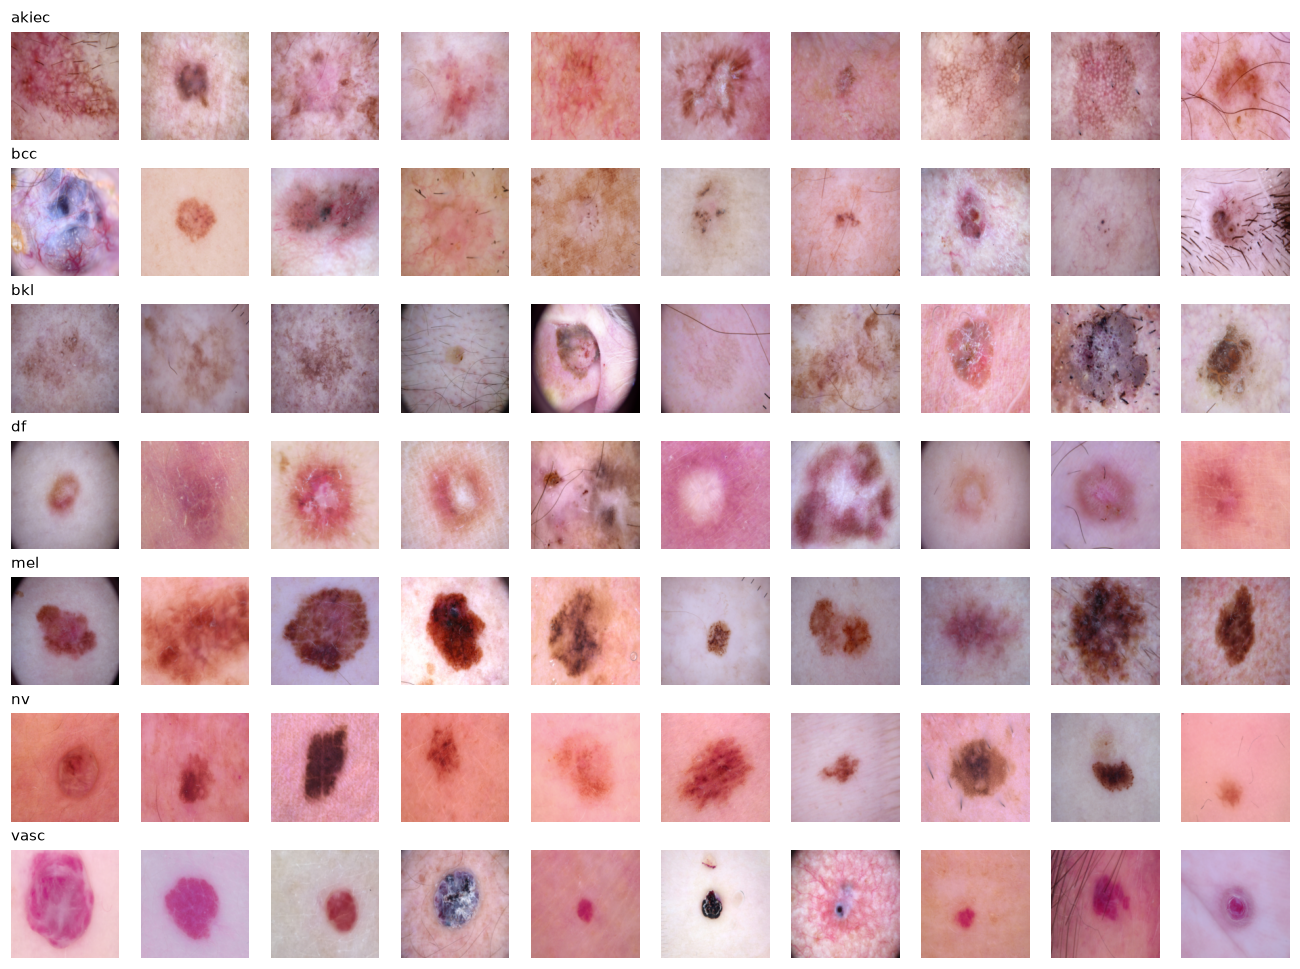

In [5]:
rng = np.random.default_rng(0)
fig, axes = plt.subplots(len(CLASSES), 10, figsize=(15, 11))
for r, c in enumerate(CLASSES):
    ids = rng.choice(df.index[df.dx == c], 10, replace=False)
    for k, i in enumerate(ids):
        axes[r, k].imshow(load_image(df.path[i], 160)); axes[r, k].axis("off")
    axes[r, 0].set_title(c, loc="left", fontsize=10)
fig.savefig("../figures/eda_contact_sheet.png", dpi=80)

## Automatic artifact flags
Rough heuristics (src/artifacts.py): dark vignette corners and dense hair (black-hat
morphology). They let us pick out artifact-heavy test images for the shortcut hunt in
notebook 05 without hand-labelling all 10k images. Ink marks and rulers are rare in
HAM10000 and colour thresholds confused ink with blue-purple pigment, so they are not
auto-flagged (a stated limitation).

In [6]:
flags = pd.DataFrame([artifact_flags(load_image(p, 224)) for p in df.path], index=df.index)
df = pd.concat([df, flags], axis=1)
df[["image_id", "dx", "split", "dark_corners", "hair"]].to_csv("../results/artifact_flags.csv", index=False)
summary = df.groupby("dx")[["dark_corners", "hair"]].mean().round(3)
summary

,dark_corners,hair
dx,,
akiec,0.031,0.214
bcc,0.043,0.136
bkl,0.099,0.172
df,0.043,0.096
mel,0.104,0.143
nv,0.024,0.092
vasc,0.007,0.106


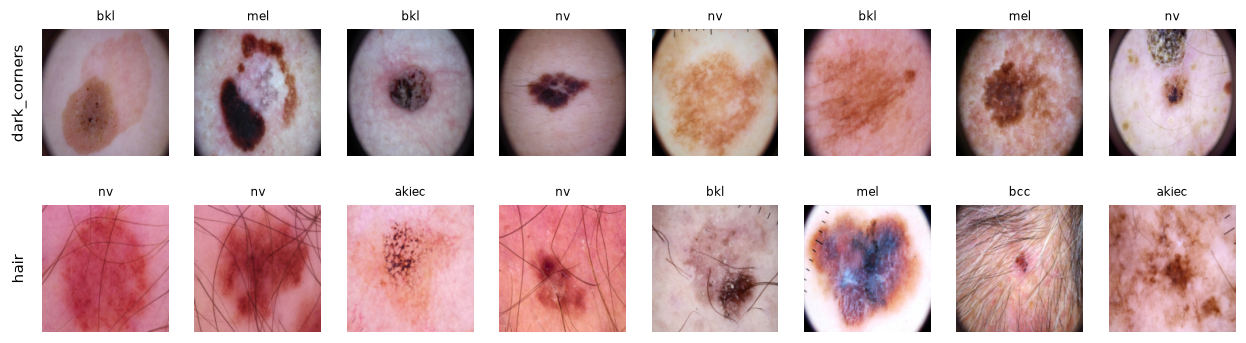

In [7]:
fig, axes = plt.subplots(2, 8, figsize=(14, 3.8))
for r, f in enumerate(["dark_corners", "hair"]):
    ids = rng.choice(df.index[df[f]], 8, replace=False)
    for k, i in enumerate(ids):
        axes[r, k].imshow(load_image(df.path[i], 160)); axes[r, k].axis("off")
        axes[r, k].set_title(df.dx[i], fontsize=8)
    axes[r, 0].text(-20, 80, f, rotation=90, va="center", ha="right", fontsize=10)
fig.savefig("../figures/eda_artifacts.png", dpi=80)

In [8]:
json.dump({"class_counts": counts.to_dict(), "artifact_rate_by_class": summary.to_dict(),
           "missing_age": int(df.age.isna().sum()),
           "unknown_localization": int((df.localization == "unknown").sum())},
          open("../results/eda.json", "w"), indent=2)